# Holmium laser pulse retrieval from a measured SHG-FROG trace


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测 → 物理目标：holmium_shg_frog_pulse_retrieval

**观测 y：** trace(1, 512, 512)；delay(1, 512)；time(1, 512)；angular_frequency(1, 512)。具体单位以本Notebook数据表及README为准。

**恢复目标 x：** 512采样时间域复光脉冲包络。

**GT/参考来源：** **没有独立GT：以下仅为原方法参考重建，不能解释为物理真值。**

**由观测恢复目标：** SHG-FROG延迟自门控信号的Fourier模平方。本地路径为 `main.reconstruct→Retriever.run(COPRA)`。现有Notebook包含主动调用路径；本次只读审核未重跑，保留的execution_count/图像只说明已有输出，不能声称本轮执行。

**现有实验与图：** 保留图像输出位于cell 1, 3, 5, 7, 9（cell编号按文件内从0计）。章节包括：# Holmium laser pulse retrieval from a measured SHG-FROG trace；## 2. Physics: fractional delays and the complex field；## 3. Method: local projection and global residual descent；## 4. Results: method agreement and observation consistency；## 5. Sensitivity, ambiguity and poor controls；## 6. Conclusion and provenance。应联合阅读观测图、完整恢复目标、参考差异与残差/敏感性实验；方法一致性不等于物理精度。

**限制：** 时间场反演而非空间图像；固定相位、时间和反转歧义约定，无独立脉冲GT。

<!-- inverse-evidence-audit:20261026:end -->


This notebook actively reconstructs the complete512×512 processed **Regen experimental acquisition**, then compares original and cleaned COPRA, PIE and an explicitly regridded PCGPA diagnostic. The target is a512-sample **temporal complex envelope**, not a spatial image. The historical author pulse is not truth. The moderate uncertainty of weak phase structure is part of the result.

## 1. Problem and observations

An electronic detector records intensity rather than optical phase. Two delayed copies of one pulse interact through second-harmonic generation; the resulting delay–frequency image constrains both amplitude and phase. All processed samples are retained. The author's background subtraction, extraction, centering and resampling preceded this task. The primary delays remain exactly those in the record.

Figure1 caption: white pixels in the logarithmic panel are **exactly zero recorded intensity**, where the logarithm is undefined; they do not denote missing measurements. The linear panel displays the same zeros in black.


{
  "python": "D:\\yan1\\agent\\AutoSkill\\imaging-101-maintainer\\research-runtime\\Scripts\\python.exe",
  "numpy": "2.4.6",
  "scipy": "1.17.1",
  "matplotlib": "3.11.1",
  "backend": "module://matplotlib_inline.backend_inline",
  "data_sha256": "552e86f121d34ff1d44be76e465b97c9437848eaa3f3c9a8b09f903f95856937"
}
Scan delay fs: 30.096000000000156 Fourier time fs: 30.116847910804346


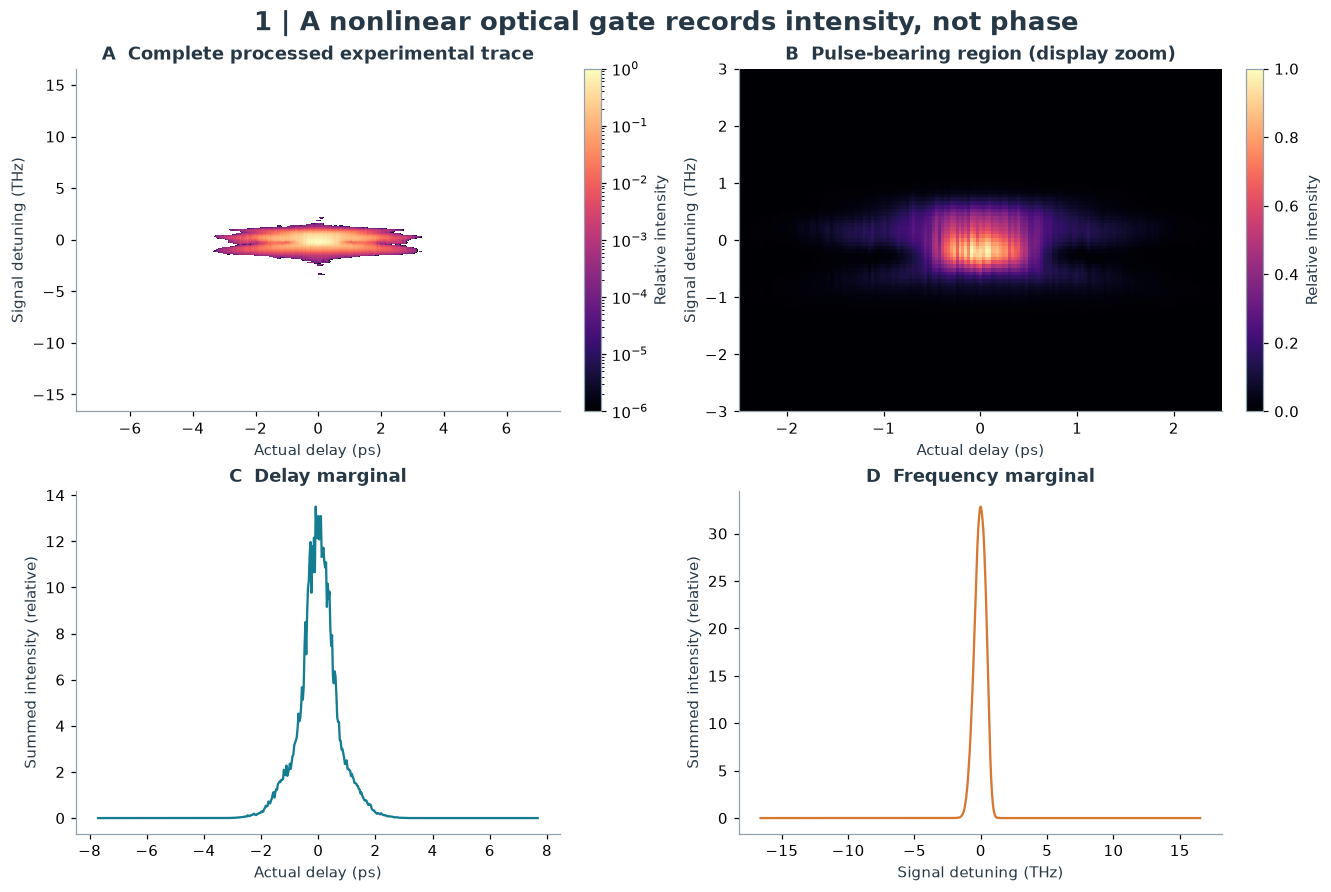

In [1]:
import os,sys,time,json,hashlib,tempfile,importlib.util
from pathlib import Path
os.environ.update(OMP_NUM_THREADS='1',OPENBLAS_NUM_THREADS='1',MKL_NUM_THREADS='1')
import numpy as np,scipy,matplotlib
import matplotlib.pyplot as plt
TASK=Path.cwd()
if not (TASK/'src').is_dir(): TASK=TASK.parent
sys.path.insert(0,str(TASK))
from src.preprocessing import load_observations,gaussian_initialization,unit_energy_field,regrid_for_pcgpa
from src.physics_model import scaled_residual
from src.solvers import Retriever
from src.main import reconstruct
from src import visualization as vis
spec=importlib.util.spec_from_file_location('frog_judge',TASK/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
FIGURES=Path(os.environ.get('FROG_FIGURE_DIR',tempfile.mkdtemp(prefix='frog_figures_')))
FIGURES.mkdir(parents=True,exist_ok=True)
measured,model=load_observations(TASK/'data/raw_data.npz');grid=model.grid
environment=dict(python=sys.executable,numpy=np.__version__,scipy=scipy.__version__,matplotlib=matplotlib.__version__,backend=matplotlib.get_backend(),data_sha256=hashlib.sha256((TASK/'data/raw_data.npz').read_bytes()).hexdigest())
print(json.dumps(environment,indent=2))
assert np.__version__=='2.4.6' and scipy.__version__=='1.17.1'
print('Scan delay fs:',np.median(np.diff(model.delays))*1e15,'Fourier time fs:',grid.dt*1e15)
vis.acquisition(measured,model,FIGURES);plt.show()


## 2. Physics: fractional delays and the complex field

For time samples $t_k$, envelope detunings $\omega_n$ and actual delays $\tau_m$, define the Fourier pair and gated field

$$F(x)_n=\frac{\Delta t}{2\pi}\sum_kx_ke^{i\omega_nt_k},\qquad B(a)_k=\Delta\omega\sum_na_ne^{-it_k\omega_n},$$
$$E=B(a),\quad A_m=B(e^{i\tau_m\omega}a),\quad S_m=A_mE,\quad T_m=|F(S_m)|^2.$$

Here $a$ is the complex envelope spectrum, $E$ is the temporal envelope, $A$ its fractionally delayed copy, $S$ the second-harmonic signal and $T$ the predicted detector intensity. The supplied signal frequencies are $\Omega=2\omega_0+\omega$. The grid is periodic and satisfies $N\Delta t\Delta\omega=2\pi$. The actual scan spacing30.096fs differs from the Fourier spacing30.11685fs. Integer rolls would silently change this model.

The output scale is fixed by $\Delta t\sum|E|^2=1$. A positive detector gain remains unobservable. No absolute pulse energy or independently calibrated noise variance is claimed. The flat effective response/thin-crystal model leaves structured experimental residuals.

Symbol definitions: $N=512$ is the number of frequency samples per row and temporal samples of the envelope; $M=512$ is the number of actual scan delays. $\Delta t$ and $\Delta\omega$ are the time and angular-frequency increments, respectively. $\omega_0$ is the given fundamental carrier angular frequency.


Fresh primary reconstruction seconds: 68.3199947999965
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "complex_relative_l2": 1.4507248258626062e-08,
    "coherent_overlap": 0.9999999999999998,
    "energy_relative_error": 0.0,
    "trace_R": 0.0022525655438589364
  },
  "thresholds": {
    "complex_relative_l2": {
      "comparison": "<=",
      "boundary": 0.30556698849660524
    },
    "coherent_overlap": {
      "comparison": ">=",
      "boundary": 0.9533144077705578
    },
    "trace_R": {
      "comparison": "<=",
      "boundary": 0.0024743633399606463
    },
    "energy_relative_error": {
      "comparison": "<=",
      "boundary": 1e-06
    }
  },
  "errors": []
}


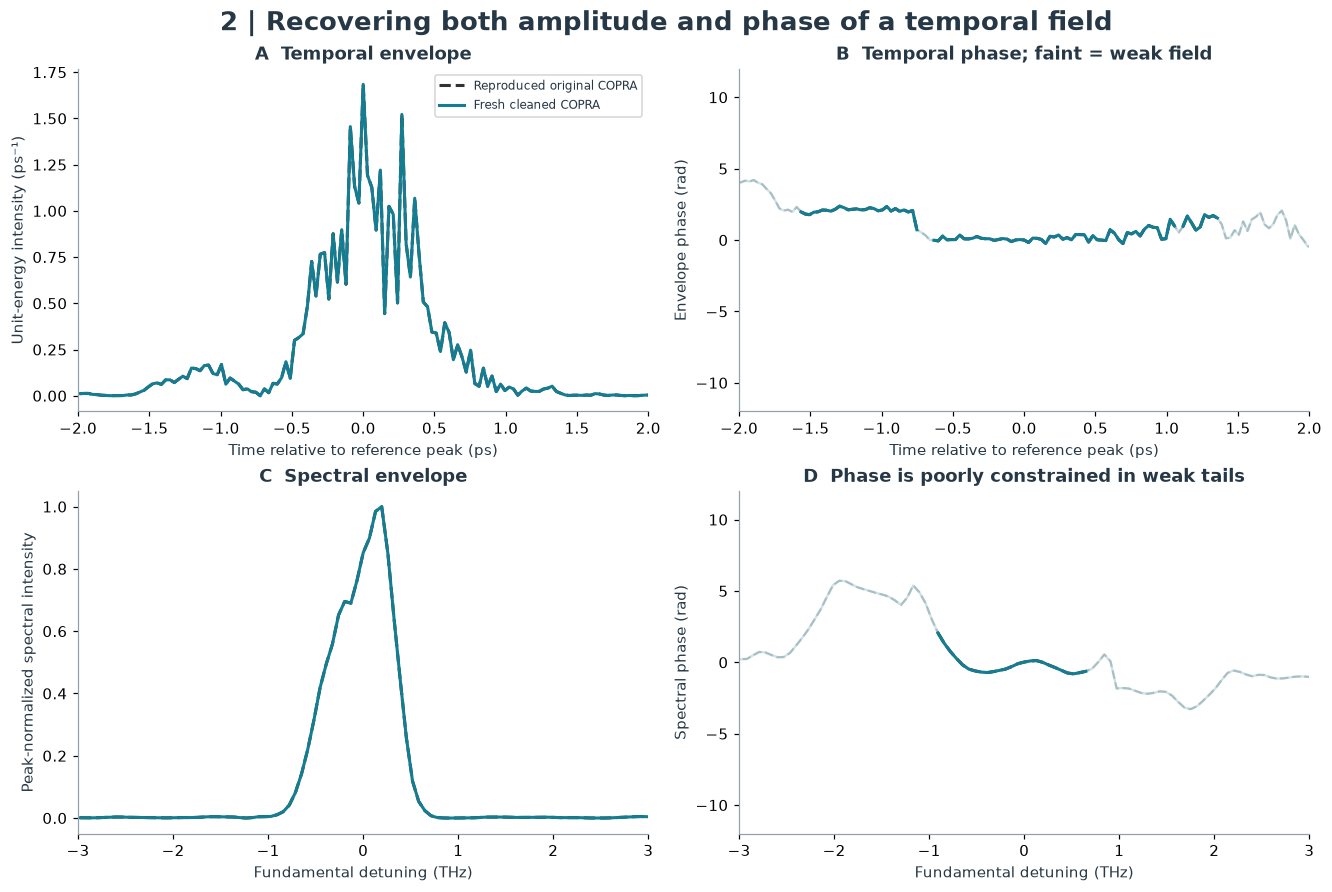

In [2]:
started=time.perf_counter()
field,result,model=reconstruct(TASK/'data/raw_data.npz')
fresh_seconds=time.perf_counter()-started
np.savez_compressed(TASK/'output/reconstruction.npz',reconstruction=field[None])
with np.load(TASK/'evaluation/baseline_reference.npz',allow_pickle=False) as f: reference=f['reconstruction'][0]
alignment=judge.align_field(field,reference,grid.dw)
report,exitcode=judge.evaluate(TASK/'output/reconstruction.npz')
assert exitcode==0,report
(TASK/'output/judge_report.json').write_text(json.dumps(report,indent=2),encoding='utf8')
print('Fresh primary reconstruction seconds:',fresh_seconds)
print(json.dumps(report,indent=2))
vis.pulse(field,reference,model,alignment,FIGURES);plt.show()


## 3. Method: local projection and global residual descent

For measured trace $D$ and current prediction $T$, least squares fits

$$\mu=\frac{\sum DT}{\sum T^2},\quad r=\sum(D-\mu T)^2,\quad R=\sqrt{r/(MN\max(D)^2)}.$$

COPRA initially permutes the delay rows, projects the Fourier signal magnitude onto $\sqrt{D/\mu}$, and updates the pulse using both derivatives of its delayed product. It then switches to global residual descent when the selected source's stagnation count reaches five. Both global steps use $\alpha=0.25$; the standard run has1000 iterations and an independent50fs Gaussian initialization.

For projected signal $P$ and $\delta=P-S$, the per-delay complex signal gradient is

$$g_m=-\frac{4\pi\Delta\omega}{\Delta t}\left[H_m^*F(\delta_mE^*)+F(\delta_mA_m^*)\right],\qquad H_m=e^{i\tau_m\omega}.$$

The local step divides the signal loss by the maximum current/previous squared gradient norm. Global steps descend the full intensity residual in signal space and then enforce the delayed-product field factorization. The original source's old-input best-save and logging conventions are preserved and independently tested. Local mixed-row errors are approximate selection statistics; all displayed physical trace residuals are recomputed from the returned complete field.

The arXivv1 main text describes ten stagnation steps whereas the selected source uses five. Its amplitude-projection gain prefactors also contain inconsistent printed notation; the source's constraint $|F(P)|^2=D/\mu$ is independently verified by direct Fourier checks. These differences are disclosed rather than silently reinterpreted.

In these expressions, $\mu$ is the fitted positive detector gain, $r$ is the intensity residual sum of squares, and $R$ is the RMS intensity residual normalized by the maximum observed intensity. A superscript $*$ in an elementwise expression denotes complex conjugation, rather than matrix transposition.


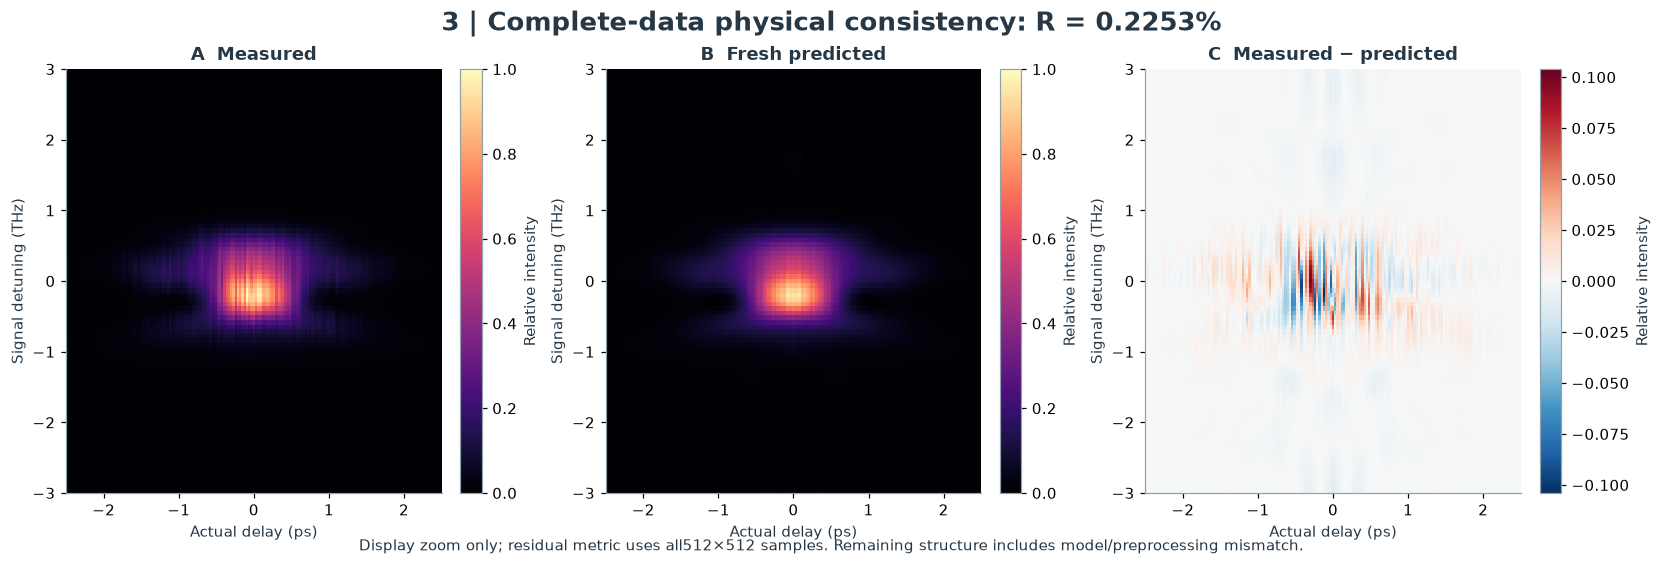

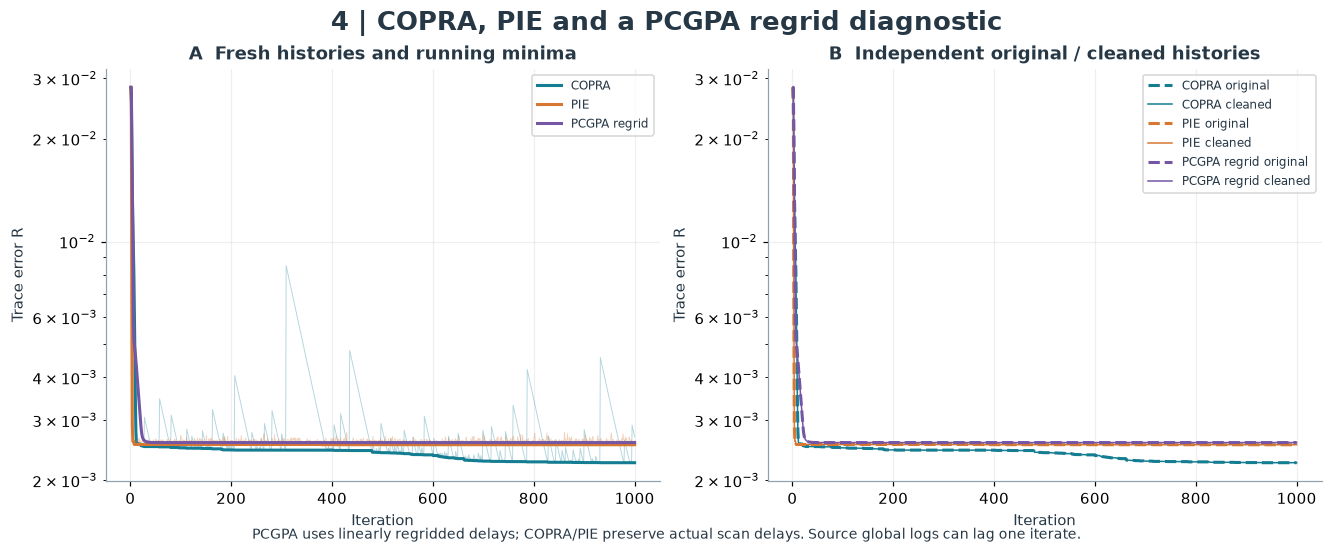

In [3]:
vis.residuals(measured,model,result['spectrum'],FIGURES);plt.show()
# Fresh computed comparison methods, not substitutions from archived outputs.
initial=gaussian_initialization(grid)
pie=Retriever(model,measured,initial,method='pie',seed=1234).run(1000)
pcdata,pcmodel=regrid_for_pcgpa(measured,model)
pcgpa=Retriever(pcmodel,pcdata,initial,method='pcgpa',seed=1234).run(1000)
fresh={'COPRA':result,'PIE':pie,'PCGPA regrid':pcgpa}
upstream={}
for label,name in [('COPRA','regen_seed1234'),('PIE','regen_pie'),('PCGPA regrid','regen_pcgpa')]:
    with np.load(TASK/f'notebooks/reference_outputs/upstream_{name}.npz',allow_pickle=False) as f:upstream[label]={k:f[k] for k in f.files}
vis.convergence(fresh,upstream,FIGURES);plt.show()


## 4. Results: method agreement and observation consistency

The reproduced original run and fresh cleaned measurements are distinct sources. Agreement with a method reference is not agreement with independently known physical truth. All512 complex samples are compared after only global phase, continuous periodic translation and optional conjugate time reversal. No frequency shift, weak-tail mask or magnitude-only comparison is allowed.

PIE uses the original fractional delays. PCGPA's outer-product rearrangement assumes a matching delay/time grid; its comparison explicitly linearly regrids delays and fills outside support with zero. Its quality below is assessed again on the **original observations**. This altered comparison condition is never used for primary COPRA or PIE.

The paper's task-relevant COPRA/PIE/PCGPA groups are retained. Its generic LM and other nonlinear modalities belong to separate simulated experiments, rather than this512-point real acquisition; no uncomputed group is plotted.

{
  "COPRA": {
    "trace_R": 0.002252565543858924,
    "complex_relative_l2": 1.4507248258626062e-08,
    "coherent_overlap": 0.9999999999999998,
    "runtime_seconds": 68.22776809999777,
    "relative_spectrum_parity_error": 0.0
  },
  "PIE": {
    "trace_R": 0.0025876067409720547,
    "complex_relative_l2": 0.23690236172538665,
    "coherent_overlap": 0.9719386355044668,
    "runtime_seconds": 110.17141249999986,
    "relative_spectrum_parity_error": 0.0
  },
  "PCGPA regrid": {
    "trace_R": 0.0025949697892908965,
    "complex_relative_l2": 0.23444217176606694,
    "coherent_overlap": 0.9725184340488048,
    "runtime_seconds": 56.90625140001066,
    "relative_spectrum_parity_error": 0.0
  }
}


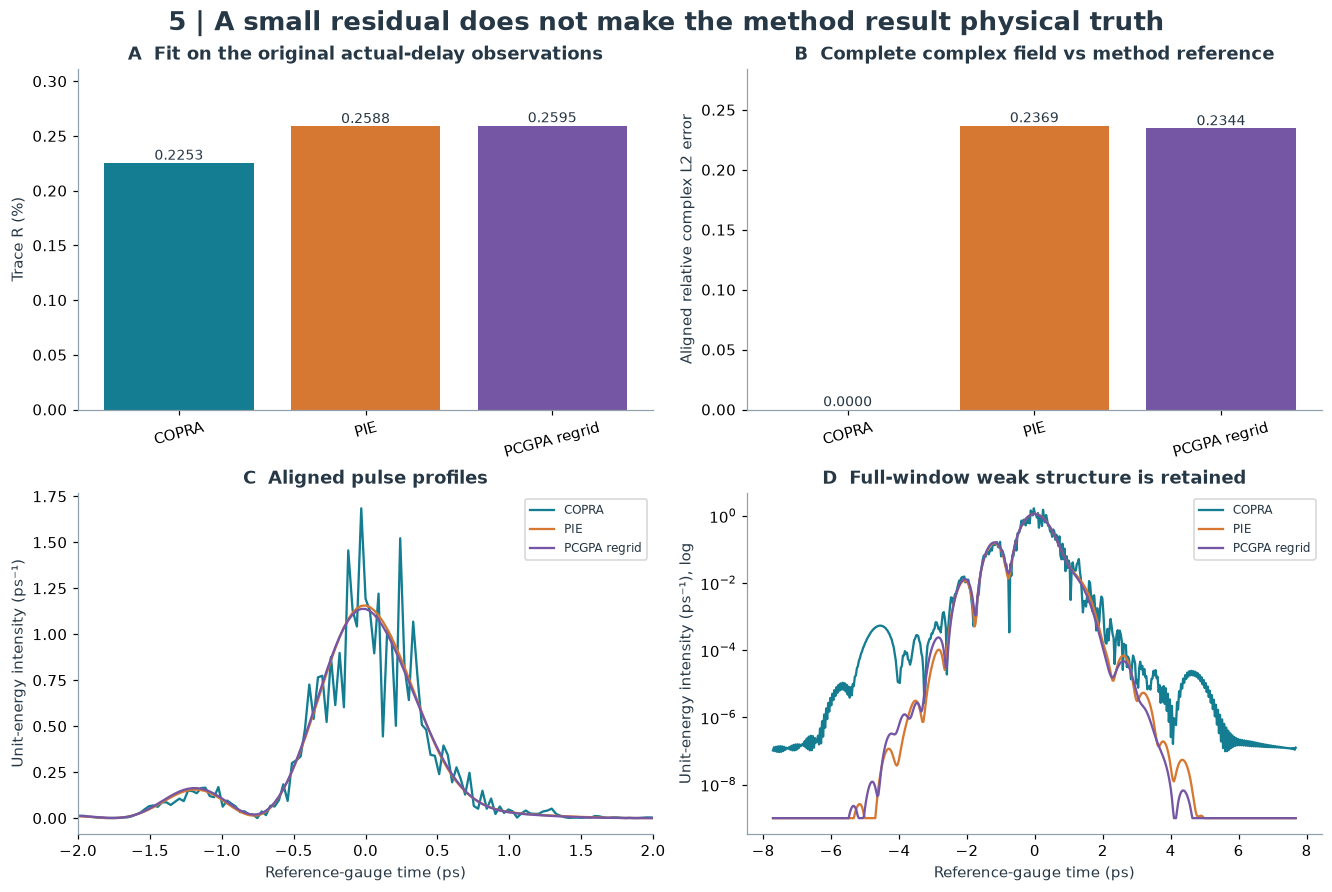

In [4]:
comparison_rows={};profiles={};numeric={'measured':measured,'delay_seconds':model.delays,'time_seconds':grid.t,'angular_detuning':grid.w,'fresh_field':field,'upstream_reference_field':reference}
for label,item in fresh.items():
    e=unit_energy_field(grid,item['spectrum']);al=judge.align_field(e,reference,grid.dw)
    R,gain,_=scaled_residual(measured,model.trace(item['spectrum']))
    comparison_rows[label]=dict(trace_R=R,complex_relative_l2=al['complex_relative_l2'],coherent_overlap=al['coherent_overlap'],runtime_seconds=item['runtime_seconds'])
    profiles[label]=vis.aligned_field(e,reference,al,grid)
    numeric[label.replace(' ','_')+'_spectrum']=item['spectrum'];numeric[label.replace(' ','_')+'_trace_history']=item['trace_error'];numeric[label.replace(' ','_')+'_predicted_trace']=gain*model.trace(item['spectrum'])
    delta=np.linalg.norm(item['spectrum']-upstream[label]['spectrum'])/np.linalg.norm(upstream[label]['spectrum'])
    comparison_rows[label]['relative_spectrum_parity_error']=float(delta)
print(json.dumps(comparison_rows,indent=2))
vis.comparisons(comparison_rows,profiles,model,FIGURES);plt.show()


## 5. Sensitivity, ambiguity and poor controls

Independent original runs varied the delay-order seed, initial intensity width and run length. Their differences are scientific uncertainty evidence, separate from implementation parity. The long runs continue an independent1000-step result for5000 additional source iterations; they do not use a historical author pulse.

The full-field bound was frozen at1.1 times the largest independent original complex discrepancy: approximately0.30557 relative complex L2, with equivalent coherent overlap at least0.95331. The independent trace gate is approximately0.24744%. This represents moderate method-reference uncertainty, **not high-precision optical phase truth**. Both amplitude and phase remain evaluated over the entire window. Faint phases in Figure2 mark weak intensity, where phase interpretation is especially uncertain.

To check that these gates remain useful, compute independent Gaussian pulses, remove phase, shuffle the complex field and assign random phase. The trace criterion and full-complex criterion reject these poor controls. Fresh global-stage-only sensitivity comparisons start from the same freshly reconstructed COPRA best field and explicitly force200 global updates at each alpha. This isolates the published global update rather than comparing an early local phase where alpha is inactive. Actual local/global counts and mode arrays are saved. An archived result is never relabeled as a fresh reconstruction.

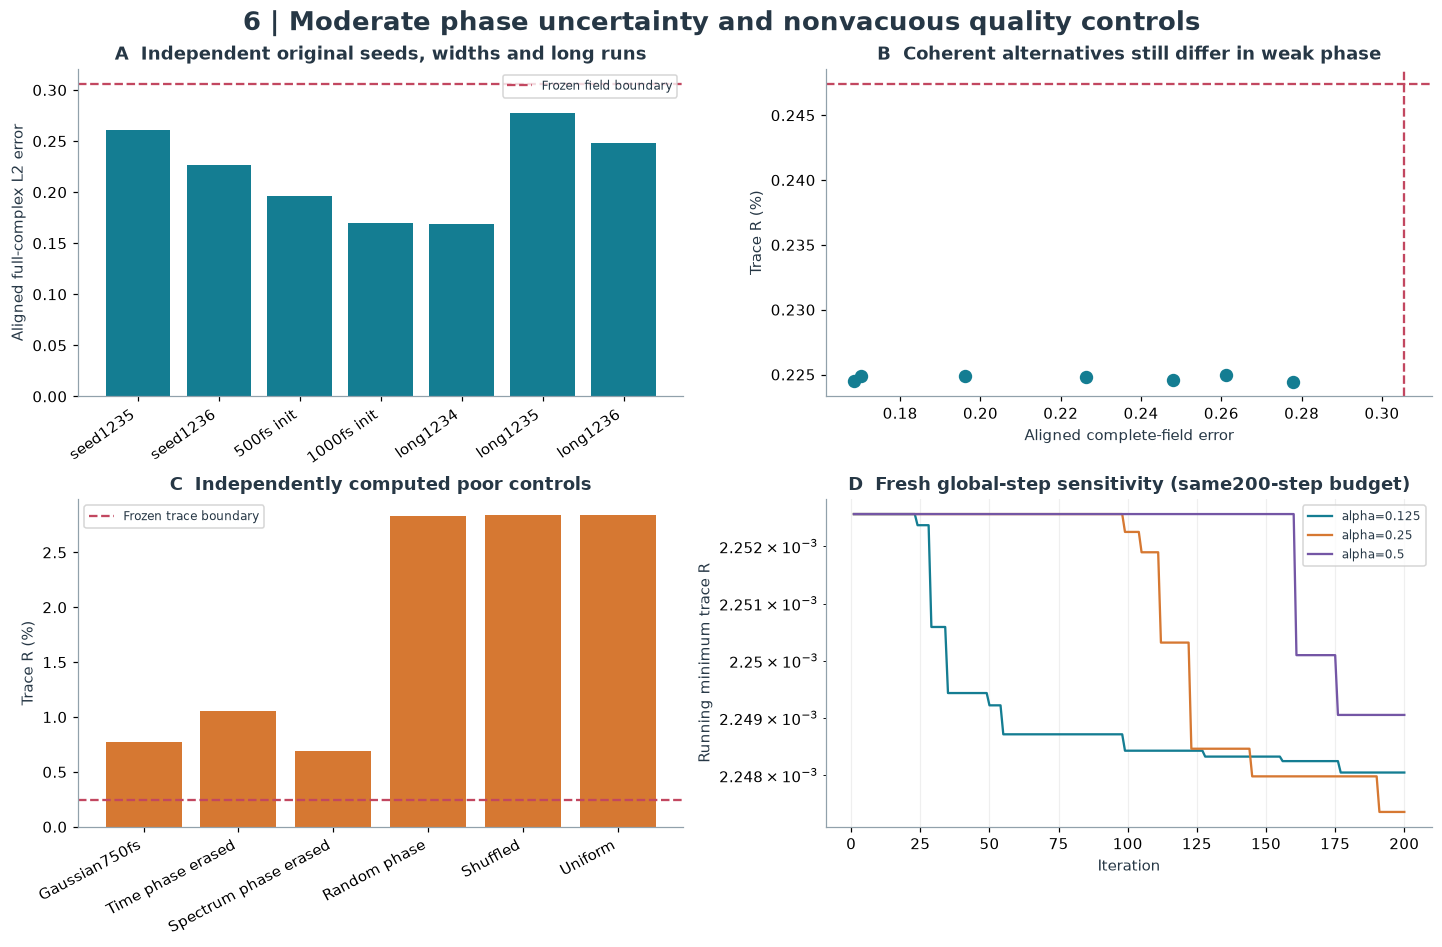

Independent original stability: {
  "seed1235": {
    "trace_R": 0.0022494212181460417,
    "complex_relative_l2": 0.2610470882868267,
    "coherent_overlap": 0.9659272088484847
  },
  "seed1236": {
    "trace_R": 0.0022477774174418648,
    "complex_relative_l2": 0.22632054699197576,
    "coherent_overlap": 0.9743895050046263
  },
  "500fs init": {
    "trace_R": 0.002248573216378383,
    "complex_relative_l2": 0.1962012975128846,
    "coherent_overlap": 0.9807525254271302
  },
  "1000fs init": {
    "trace_R": 0.00224881063263886,
    "complex_relative_l2": 0.1702589490211951,
    "coherent_overlap": 0.9855059451390991
  },
  "long1234": {
    "trace_R": 0.0022452912025115058,
    "complex_relative_l2": 0.1684865256367302,
    "coherent_overlap": 0.9858061453394316
  },
  "long1235": {
    "trace_R": 0.00224461110653339,
    "complex_relative_l2": 0.2777881713605502,
    "coherent_overlap": 0.9614168659260808
  },
  "long1236": {
    "trace_R": 0.0022456629337720396,
    "complex_rela

4858

In [5]:
stability={}
for label,name in [('seed1235','regen_seed1235'),('seed1236','regen_seed1236'),('500fs init','regen_width500'),('1000fs init','regen_width1000'),('long1234','regen_long_seed1234'),('long1235','regen_long_seed1235'),('long1236','regen_long_seed1236')]:
    with np.load(TASK/f'notebooks/reference_outputs/upstream_{name}.npz',allow_pickle=False) as f:sp=f['spectrum']
    e=unit_energy_field(grid,sp);al=judge.align_field(e,reference,grid.dw);R=scaled_residual(measured,model.trace(sp))[0]
    stability[label]=dict(trace_R=R,complex_relative_l2=al['complex_relative_l2'],coherent_overlap=al['coherent_overlap']);numeric['independent_'+name+'_field']=e
rng=np.random.RandomState(91)
control_fields={'Gaussian750fs':np.exp(-2*np.log(2)*(grid.t/750e-15)**2).astype(complex),'Time phase erased':abs(reference).astype(complex),'Spectrum phase erased':grid.backward(abs(grid.forward(reference))),'Random phase':abs(reference)*np.exp(1j*rng.uniform(-np.pi,np.pi,grid.n)),'Shuffled':rng.permutation(reference),'Uniform':np.ones(grid.n,dtype=complex)}
controls={}
for name,e in control_fields.items():
    al=judge.align_field(e/np.sqrt(np.sum(abs(e)**2)*grid.dt),reference,grid.dw);R=judge.trace_error(e,measured,model.delays,grid.dw)
    controls[name]=dict(trace_R=R,complex_relative_l2=al['complex_relative_l2'],coherent_overlap=al['coherent_overlap'])
sensitivity={}
for alpha in [.125,.25,.5]:
    probe=Retriever(model,measured,result['spectrum'],alpha=alpha,seed=1234)
    probe.mode='global'  # Explicit diagnostic: same fresh primary best, global stage only.
    sensitivity[f'alpha={alpha}']=probe.run(200)
    assert np.count_nonzero(sensitivity[f'alpha={alpha}']['mode'])==200
definition=json.loads((TASK/'evaluation/metrics.json').read_text());bounds=definition['thresholds']
vis.uncertainty(stability,controls,sensitivity,FIGURES,bounds['complex_relative_l2']['boundary'],bounds['trace_R']['boundary']);plt.show()
print('Independent original stability:',json.dumps(stability,indent=2))
print('Fresh poor controls:',json.dumps(controls,indent=2))
for name,item in sensitivity.items():
    numeric['sensitivity_'+name+'_history']=item['trace_error']
    numeric['sensitivity_'+name+'_mode']=item['mode']
    print(name,'global steps',int(np.count_nonzero(item['mode'])),'local steps',int(np.count_nonzero(item['mode']==0)))
np.savez_compressed(FIGURES/'plot_numeric_sources.npz',**numeric)
measurements=dict(environment=environment,primary_runtime_seconds=fresh_seconds,comparison_rows=comparison_rows,independent_original_stability=stability,fresh_controls=controls,sensitivity={k:dict(actual_error=v['actual_error'],runtime_seconds=v['runtime_seconds'],global_iterations=int(np.count_nonzero(v['mode'])),local_iterations=int(np.count_nonzero(v['mode']==0)),initialization='Shared freshly reconstructed primary best; force global stage') for k,v in sensitivity.items()},judge=report)
(FIGURES/'computed_measurements.json').write_text(json.dumps(measurements,indent=2,allow_nan=False),encoding='utf8')


## 6. Conclusion and provenance

The cleaned method reconstructs the complete processed experimental observation with explicit local Fourier, nonlinear gate, projection and complex-gradient updates. Reproduced original and fresh results agree numerically, and independent physical checks cover Fourier quadrature, Parseval normalization, fractional delays, absolute Gaussian SHG scaling and directional derivatives. The observations constrain a coherent temporal field, with meaningful uncertainty in weak structure. An excellent method-reference match is not independent physical truth.

Method: Geib etal., *Optica*6,495–505(2019), DOI10.1364/OPTICA.6.000495, arXiv1810.04780v1. Experiment: Suzuki etal., arXiv2412.09096v1. Real author-processed Regen data: Zenodo14390876, CC BY4.0. Original source revision, paper/data hashes, isolated oracle environment, frozen stage fixtures, actual command logs and per-gate evidence are indexed in `test/validation.md`. All plotted fresh methods were computed in this execution; the explicitly labeled independent original ensembles were reproduced separately.